# Team 8 — Emotion Detection from Text (NLP)

**Project category:** Emotion classification  
**Assigned teams:** 6 and 8  
**Environment:** Google Colab / Jupyter Notebook  
**Application:** Streamlit

## Project objective
Build an NLP application that predicts the emotion expressed in a short text. This notebook uses a manageable set of GoEmotions labels, preprocesses the text, compares two machine-learning models, evaluates their performance, saves the best pipeline, and prepares a Streamlit app.

**Important:** Emotion predictions are estimates based on patterns in the dataset. They do not establish a person's actual emotional state.

### Workflow
1. Install and import libraries
2. Load and inspect GoEmotions
3. Select six emotion classes and prepare data
4. Split data and train two models using TF-IDF
5. Compare models using accuracy, macro-F1, precision, recall, and confusion matrix
6. Save the best pipeline
7. Test custom sentences
8. Create `app.py` and `requirements.txt` for Streamlit


In [ ]:
# Step 1: Install required packages
!pip -q install datasets scikit-learn pandas matplotlib seaborn joblib streamlit


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.3/10.3 MB 27.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 44.5 MB/s eta 0:00:00


In [ ]:
# Step 2: Imports and reproducibility
import re
import os
import random
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from datasets import load_dataset
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)

RANDOM_STATE = 42
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)


## Step 3: Load the dataset

We use the **GoEmotions** dataset via Hugging Face Datasets. It contains Reddit comments annotated with emotion labels. Dataset access or dataset configuration may change over time; if loading fails, check the current dataset page and documentation.

To keep the first implementation manageable and suitable for standard multiclass classifiers, this notebook keeps examples that have **exactly one** label from these six selected classes: `joy`, `sadness`, `anger`, `fear`, `surprise`, and `love`. Examples with multiple labels or other labels are excluded from this baseline experiment.


In [ ]:
# Load the simplified GoEmotions dataset
dataset = load_dataset("google-research-datasets/go_emotions", "simplified")

print(dataset)
print("Available labels:", dataset["train"].features["labels"].feature.names)


README.md:   0%|          | 0.00/9.40k [00:00<?, ?B/s]

simplified/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 2.77MB            

simplified/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

simplified/validation-00000-of-00001.par(…): reconstructing file:   0%|          |  0.00B /  350kB            

simplified/validation-00000-of-00001.par(…): downloading bytes:           |  0.00B            

...

simplified/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/43410 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/5426 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/5427 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'labels', 'id'],
        num_rows: 43410
    })
    validation: Dataset({
        features: ['text', 'labels', 'id'],
        num_rows: 5426
    })
    test: Dataset({
        features: ['text', 'labels', 'id'],
        num_rows: 5427
    })
})
Available labels: ['admiration', 'amusement', 'anger', 'annoyance', 'approval', 'caring', 'confusion', 'curiosity', 'desire', 'disappointment', 'disapproval', 'disgust', 'embarrassment', 'excitement', 'fear', 'gratitude', 'grief', 'joy', 'love', 'nervousness', 'optimism', 'pride', 'realization', 'relief', 'remorse', 'sadness', 'surprise', 'neutral']


In [ ]:
# Convert records to a DataFrame and inspect the data
label_names = dataset["train"].features["labels"].feature.names

train_raw = pd.DataFrame(dataset["train"])
validation_raw = pd.DataFrame(dataset["validation"])
test_raw = pd.DataFrame(dataset["test"])

display(train_raw.head())
print("Train shape:", train_raw.shape)
print("Missing text values:", train_raw["text"].isna().sum())


,text,labels,id
0,My favourite food is anything I didn't have to...,[27],eebbqej
1,"Now if he does off himself, everyone will thin...",[27],ed00q6i
2,WHY THE FUCK IS BAYLESS ISOING,[2],eezlygj
3,To make her feel threatened,[14],ed7ypvh
4,Dirty Southern Wankers,[3],ed0bdzj


Train shape: (43410, 3)
Missing text values: 0


## Step 4: Select and prepare emotion classes

We filter to examples with exactly one of the six selected emotions. This creates a single-label multiclass task. We remove missing and duplicate text records and use a stratified split so that each emotion is represented proportionally in the train and test sets.


In [ ]:
TARGET_EMOTIONS = ["joy", "sadness", "anger", "fear", "surprise", "love"]
target_ids = {label_names.index(name): name for name in TARGET_EMOTIONS}

def prepare_single_label_frame(frame):
    rows = []
    for _, row in frame.iterrows():
        labels = row["labels"]
        if not isinstance(labels, (list, tuple, np.ndarray)) or len(labels) != 1:
            continue
        label_id = int(labels[0])
        if label_id in target_ids:
            text = row["text"]
            if isinstance(text, str) and text.strip():
                rows.append({"text": text.strip(), "emotion": target_ids[label_id]})
    out = pd.DataFrame(rows)
    if not out.empty:
        out = out.drop_duplicates(subset=["text"]).reset_index(drop=True)
    return out

# Combine official splits before making a fresh stratified train/test split.
all_raw = pd.concat([train_raw, validation_raw, test_raw], ignore_index=True)
data = prepare_single_label_frame(all_raw)

if data.empty:
    raise ValueError("No examples matched the selected labels. Check the current dataset label format.")

print("Prepared dataset shape:", data.shape)
display(data.head())
print("\nClass counts:")
display(data["emotion"].value_counts().rename_axis("emotion").to_frame("count"))


Prepared dataset shape: (6491, 2)


,text,emotion
0,WHY THE FUCK IS BAYLESS ISOING,anger
1,To make her feel threatened,fear
2,OmG pEyToN iSn'T gOoD eNoUgH tO hElP uS iN tHe...,surprise
3,Fucking coward.,anger
4,Stupidly stubborn / stubbornly stupid,anger



Class counts:


,count
emotion,
love,1730
anger,1262
joy,1048
sadness,1000
surprise,900
fear,551


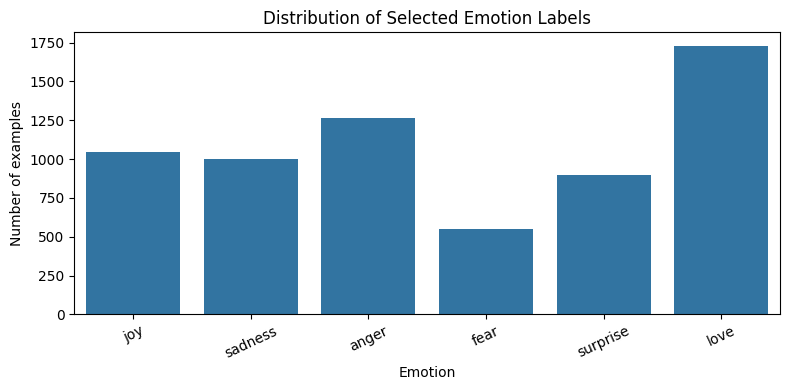

In [ ]:
# Visualize class distribution
plt.figure(figsize=(8, 4))
sns.countplot(data=data, x="emotion", order=TARGET_EMOTIONS)
plt.title("Distribution of Selected Emotion Labels")
plt.xlabel("Emotion")
plt.ylabel("Number of examples")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()


## Step 5: Text preprocessing and train/test split

A scikit-learn pipeline applies TF-IDF only to the training data during fitting, which helps avoid data leakage. We keep preprocessing relatively light so that useful context and negation are not accidentally removed.


In [ ]:
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"https?://\S+|www\.\S+", " URL ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

data["clean_text"] = data["text"].apply(clean_text)

X_train, X_test, y_train, y_test = train_test_split(
    data["clean_text"],
    data["emotion"],
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=data["emotion"]
)

print("Training examples:", len(X_train))
print("Testing examples:", len(X_test))
print("Training class distribution:")
display(y_train.value_counts())


Training examples: 5192
Testing examples: 1299
Training class distribution:


,count
emotion,
love,1384
anger,1009
joy,838
sadness,800
surprise,720
fear,441


## Step 6: Train and compare two models

Both models use the same TF-IDF representation and the same train/test split:
- **Multinomial Naive Bayes**
- **Logistic Regression**

The final model will be selected based on macro-F1, which gives each emotion class equal weight and is useful when class frequencies differ.


In [ ]:
models = {
    "Multinomial Naive Bayes": Pipeline([
        ("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_features=100000)),
        ("classifier", MultinomialNB())
    ]),
    "Logistic Regression": Pipeline([
        ("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_features=100000)),
        ("classifier", LogisticRegression(max_iter=1500, class_weight="balanced", random_state=RANDOM_STATE))
    ])
}

results = []
trained_models = {}

for model_name, pipeline in models.items():
    print(f"Training {model_name}...")
    pipeline.fit(X_train, y_train)
    predictions = pipeline.predict(X_test)
    trained_models[model_name] = pipeline
    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision (macro)": precision_score(y_test, predictions, average="macro", zero_division=0),
        "Recall (macro)": recall_score(y_test, predictions, average="macro", zero_division=0),
        "F1-score (macro)": f1_score(y_test, predictions, average="macro", zero_division=0)
    })

results_df = pd.DataFrame(results).sort_values("F1-score (macro)", ascending=False).reset_index(drop=True)
display(results_df)


Training Multinomial Naive Bayes...
Training Logistic Regression...


,Model,Accuracy,Precision (macro),Recall (macro),F1-score (macro)
0,Logistic Regression,0.801386,0.785469,0.788145,0.786099
1,Multinomial Naive Bayes,0.616628,0.796556,0.529680,0.560060


## Step 7: Evaluate the selected model

The notebook selects the model with the highest test macro-F1. The displayed scores are calculated when you run the notebook; do not copy or claim results before running the experiment.


Selected model: Logistic Regression

Classification report:
              precision    recall  f1-score   support

         joy       0.82      0.78      0.80       210
     sadness       0.70      0.76      0.73       200
       anger       0.81      0.76      0.78       253
        fear       0.75      0.75      0.75       110
    surprise       0.72      0.79      0.75       180
        love       0.92      0.89      0.90       346

    accuracy                           0.80      1299
   macro avg       0.79      0.79      0.79      1299
weighted avg       0.80      0.80      0.80      1299



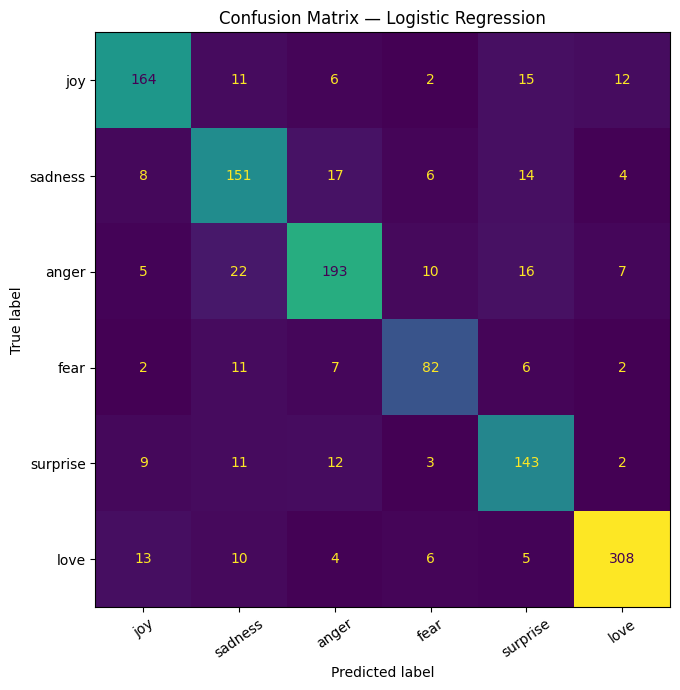

In [ ]:
best_model_name = results_df.loc[0, "Model"]
best_model = trained_models[best_model_name]
y_pred = best_model.predict(X_test)

print("Selected model:", best_model_name)
print("\nClassification report:")
print(classification_report(y_test, y_pred, labels=TARGET_EMOTIONS, zero_division=0))

cm = confusion_matrix(y_test, y_pred, labels=TARGET_EMOTIONS)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=TARGET_EMOTIONS)
fig, ax = plt.subplots(figsize=(8, 7))
disp.plot(ax=ax, xticks_rotation=35, colorbar=False)
plt.title(f"Confusion Matrix — {best_model_name}")
plt.tight_layout()
plt.show()


## Step 8: Error analysis

Inspect some incorrectly classified examples. Use these examples to discuss similar emotions, sarcasm, context, slang, and dataset annotation limitations in the report.


In [ ]:
error_analysis = pd.DataFrame({
    "text": data.loc[X_test.index, "text"].values,
    "actual": y_test.values,
    "predicted": y_pred
})
errors = error_analysis[error_analysis["actual"] != error_analysis["predicted"]]
display(errors.head(20))
print("Number of test errors:", len(errors), "out of", len(y_test))


,text,actual,predicted
1,But then you regret it because you realize you...,sadness,anger
6,That just shows how similar people can be in t...,anger,fear
10,I could crush him like a bug right now.,anger,love
13,Stop saying that ? Makes my tummy upset 🤢🤮,anger,sadness
33,"Well, my upcoming adverts are going to be inte...",joy,fear
37,Grandmas knees are burning up,sadness,anger
48,"Please, please, please don't do that to yourse...",sadness,anger
62,The real tips are always in the comments :D,joy,surprise
66,Yeah usually there are the c-1 but this go aro...,love,anger
68,"BREAKING NEWS, local bartender found chained u...",sadness,surprise


Number of test errors: 258 out of 1299


## Step 9: Save the best model

The saved scikit-learn pipeline contains both the TF-IDF vectorizer and classifier, so the app can load one file and apply the same learned representation used during training.


In [ ]:
os.makedirs("models", exist_ok=True)
MODEL_PATH = "models/emotion_detection_pipeline.joblib"
joblib.dump(best_model, MODEL_PATH)

with open("models/selected_emotions.txt", "w", encoding="utf-8") as f:
    f.write("\n".join(TARGET_EMOTIONS))

print("Saved model to:", MODEL_PATH)


Saved model to: models/emotion_detection_pipeline.joblib


## Step 10: Test custom sentences

Try different sentence styles. Predictions are model estimates, not definitive judgments about a person's emotional state.


In [ ]:
def predict_emotion(text):
    if not isinstance(text, str) or not text.strip():
        return "Please enter a non-empty sentence."
    prediction = best_model.predict([clean_text(text)])[0]
    return prediction

examples = [
    "I am so happy that I passed my exam!",
    "I feel sad because I miss my friends.",
    "I am angry that my order never arrived.",
    "I am afraid of what might happen tomorrow.",
    "Wow, I did not expect that surprise!",
    "Hi my love, what are you doing."
]

for sentence in examples:
    print(f"Text: {sentence}\nPredicted emotion: {predict_emotion(sentence)}\n")


Text: I am so happy that I passed my exam!
Predicted emotion: joy

Text: I feel sad because I miss my friends.
Predicted emotion: sadness

Text: I am angry that my order never arrived.
Predicted emotion: anger

Text: I am afraid of what might happen tomorrow.
Predicted emotion: fear

Text: Wow, I did not expect that surprise!
Predicted emotion: surprise

Text: Hi my love, what are you doing.
Predicted emotion: love



## Step 11: Create the Streamlit application

This cell writes `app.py` and `requirements.txt`. Download the saved model file from the Colab Files panel along with these files, keeping the `models/` folder structure.

For local execution, place `app.py`, `requirements.txt`, and `models/emotion_detection_pipeline.joblib` in the same project folder, then run:
```bash
pip install -r requirements.txt
streamlit run app.py
```


In [ ]:
app_code = r"""
import re
import joblib
import streamlit as st

st.set_page_config(page_title="Emotion Detection", page_icon="💬", layout="centered")

@st.cache_resource
def load_pipeline():
    return joblib.load("models/emotion_detection_pipeline.joblib")

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"https?://\\S+|www\\.\\S+", " URL ", text)
    text = re.sub(r"\\s+", " ", text).strip()
    return text

st.title("💬 Emotion Detection from Text")
st.write(
    "Enter a sentence or short message. The model estimates one emotion "
    "from joy, sadness, anger, fear, surprise, and love."
)

st.info("Predictions are estimates learned from text examples and do not establish a person's actual emotional state.")

user_text = st.text_area("Enter your text", placeholder="Example: I am excited about my new project!")
if st.button("Predict emotion", type="primary"):
    if not user_text.strip():
        st.warning("Please enter some text first.")
    else:
        pipeline = load_pipeline()
        prediction = pipeline.predict([clean_text(user_text)])[0]
        st.subheader(f"Predicted emotion: {prediction.title()}")
"""

with open("app.py", "w", encoding="utf-8") as f:
    f.write(app_code)

requirements = """datasets
scikit-learn
pandas
numpy
matplotlib
seaborn
joblib
streamlit
"""
with open("requirements.txt", "w", encoding="utf-8") as f:
    f.write(requirements)

print("Created app.py and requirements.txt")


Created app.py and requirements.txt


## Step 12: Project conclusion template

Complete this section **after running the notebook**:

- **Problem:** Detect the emotion expressed in short text.
- **Dataset:** GoEmotions, filtered to six selected single-label classes.
- **Preprocessing:** Lowercasing, URL normalization, whitespace normalization, and TF-IDF features.
- **Models compared:** Multinomial Naive Bayes and Logistic Regression.
- **Best model:** Record the model selected by test macro-F1.
- **Results:** Copy the actual metrics from `results_df` and include the confusion matrix.
- **Limitations:** Sarcasm, ambiguous language, cultural differences, annotation noise, class imbalance, and context beyond a short text.
- **Future work:** Evaluate transformer-based models, support more labels, improve calibration, and test on text from a different source.

### Submission checklist
- [ ] Notebook with executed outputs
- [ ] Dataset source and label mapping documented
- [ ] Model comparison and evaluation results
- [ ] Confusion matrix and error analysis
- [ ] Saved pipeline in `models/`
- [ ] Streamlit `app.py`
- [ ] `requirements.txt` and README
- [ ] Report and presentation
- [ ] Every team member can explain their own contribution
